# Real NASA Lebanon pipeline and reserved-year evaluation
This notebook reviews the completed **real-data retrospective** NOAA-20 run. It calls reusable Python modules, preserves the frozen model and threshold, and does not tune against test years. It is not evidence of operational forecast validation. Run the acquisition and training commands in `../README.md` first. Notebooks 01–03 remain a separate synthetic mechanics demonstration.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
from firecast.gridded import prepare_static
from firecast.train_real import train
from firecast.review import review
from firecast.inference import predict
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
DATA = ROOT / 'outputs/noaa20-real'
MODELS = DATA / 'models'
report = json.loads((DATA / 'dataset-report.json').read_text())
assert report['synthetic'] is False
print(report['label_product'], report['cells'], 'eligible cells')

VJ114A1.002 daily 1km; not FIRMS 375m 124 eligible cells


## Extract and transform actual environmental inputs
The reusable adapter reads NASA country geometry, categorical MCD12Q1.061 quality flags and SRTM elevations. It maps native pixels to the configured grid and computes terrain features. This reruns static transformation only; it does not change the training dataset.

In [2]:
config = json.loads((ROOT / 'configs/noaa20-dataset.json').read_text())
cells, maps = prepare_static(ROOT / 'data/environment', config, ROOT / 'outputs/notebook-static-review')
assert len(cells) == report['cells']
display(cells.head())

,cell_id,eligible_pixels,vegetation_fraction,elevation_m,slope_deg,aspect_sin,aspect_cos,lat,lon,cell_center_lat,cell_center_lon,region
0,1230_2151,10,0.950000,314.777778,10.476749,-0.230955,0.255295,33.095833,35.158305,33.05,35.15,lebanon
1,1230_2152,21,1.000000,494.624339,11.503528,-0.161381,-0.164395,33.087500,35.254435,33.05,35.25,lebanon
2,1230_2153,27,0.990741,633.440329,9.325579,-0.045858,-0.011016,33.087500,35.343952,33.05,35.35,lebanon
3,1230_2154,15,1.000000,724.837037,8.306779,-0.171868,-0.114446,33.087500,35.423522,33.05,35.45,lebanon
4,1231_2151,51,0.596386,163.328976,10.230231,-0.353039,0.295515,33.129167,35.171648,33.15,35.15,lebanon


## Labels, cloud uncertainty and filtering
Both fitted classes require at least 80% processed eligible area in the same daily source product. Cloudy, missing and unknown examples have null fitting labels. A removed detection quarantines the whole cell-window. Cropland is included; no claim is made that this is a certified wildland-only incident catalogue.

In [3]:
display(pd.DataFrame({p: r['statuses'] for p, r in report['policies'].items()}).fillna(0).astype(int))
f = pd.read_csv(DATA / 'dataset-strict.csv.gz')
assert f.loc[f.label_status.isin(['uncertain','excluded','positive_low_coverage']), 'y'].isna().all()
assert f.loc[f.y.notna(), 'processed_fraction'].ge(.8).all()
display(f.assign(year=pd.to_datetime(f.prediction_time).dt.year).groupby('year').agg(windows=('cell_id','size'), qualified=('y','count'), positive_windows=('y','sum')))

,conservative,strict
negative,320645,319311
uncertain,40830,40793
positive,809,612
excluded,41,1609
positive_low_coverage,3,3


,windows,qualified,positive_windows
year,,,
2018,45260,38927,32.0
2019,45260,39945,77.0
2020,45384,39765,93.0
2021,45260,40186,98.0
2022,45260,40181,32.0
2023,45260,39955,53.0
2024,45384,40313,153.0
2025,45260,40651,74.0


## Training logic and immutable later-year test
The original completed fit called `firecast.train_real.train(DATA, MODELS)`. To reproduce it in a fresh output directory, call `train(DATA, ROOT / 'outputs/reproduced-models')`; do not vary features or thresholds after reviewing test results. The pipeline fits monthly climatology first, then weather logistic regression, environmental logistic regression, and guarded histogram boosting. Strict filtering was predeclared primary; lowest **validation** Brier chooses the model. Training is 2018–2020, validation 2021–2022, and test 2023–2025 with seven-day boundary gaps. Independent incident separation has not been established.

In [4]:
metrics = json.loads((MODELS / 'metrics.json').read_text())
preflight = json.loads((MODELS / 'preflight.json').read_text())
print('Frozen selection:', metrics['selected'])
display(pd.DataFrame(preflight['counts']['strict']).T)
comparison = pd.DataFrame([dict(experiment=e['id'], validation_brier=e['validation']['brier'], test_AP=e['test']['pr_auc_average_precision'], test_brier=e['test']['brier'], precision=e['test']['precision'], recall=e['test']['recall']) for e in metrics['experiments']])
display(comparison)

Frozen selection: strict-lebanon-environment


,rows,positive_windows
train,117677,202
validation,78769,130
test,120155,280


,experiment,validation_brier,test_AP,test_brier,precision,recall
0,conservative-lebanon-seasonal,0.002106,0.006597,0.003135,0.006272,0.731579
1,conservative-lebanon-weather,0.002109,0.006644,0.003138,0.008117,0.136842
2,conservative-lebanon-environment,0.002102,0.012333,0.003127,0.011612,0.134211
3,conservative-lebanon-boosting,0.002106,0.009927,0.003140,0.019153,0.050000
4,strict-lebanon-seasonal,0.001646,0.004096,0.002322,0.004131,0.800000
5,strict-lebanon-weather,0.001648,0.004656,0.002323,0.006432,0.110714
6,strict-lebanon-environment,0.001644,0.009086,0.002317,0.013120,0.096429
7,strict-lebanon-boosting,0.001651,0.007520,0.002328,0.027027,0.017857


## Recompute diagnostics without fitting or selecting
The review module checks split identities, exports an auditable split manifest, computes score-quantile reliability and PR curves, and evaluates release evidence. Tied scores remain together. Its probabilities still concern satellite detections under the stated coverage rule.

Production release failures: ['operational_forecast_mode', 'historical_feature_availability', 'issued_forecast_backtest', 'independent_incident_split_review', 'calibration_review']


,n,positive_windows,min_probability,max_probability,mean_probability,observed_fraction
0,12016,1,2.972600e-10,0.000071,0.000039,0.000083
1,12015,0,7.129479e-05,0.000152,0.000110,0.000000
2,12016,0,1.521982e-04,0.000265,0.000205,0.000000
3,12015,5,2.647933e-04,0.000436,0.000345,0.000416
4,12015,6,4.360735e-04,0.000690,0.000555,0.000499
5,12016,10,6.898864e-04,0.001090,0.000875,0.000832
6,12015,19,1.089951e-03,0.001762,0.001396,0.001581
7,12016,51,1.761668e-03,0.002864,0.002265,0.004244
8,12015,86,2.864305e-03,0.004959,0.003777,0.007158
9,12016,102,4.958758e-03,0.052679,0.008500,0.008489


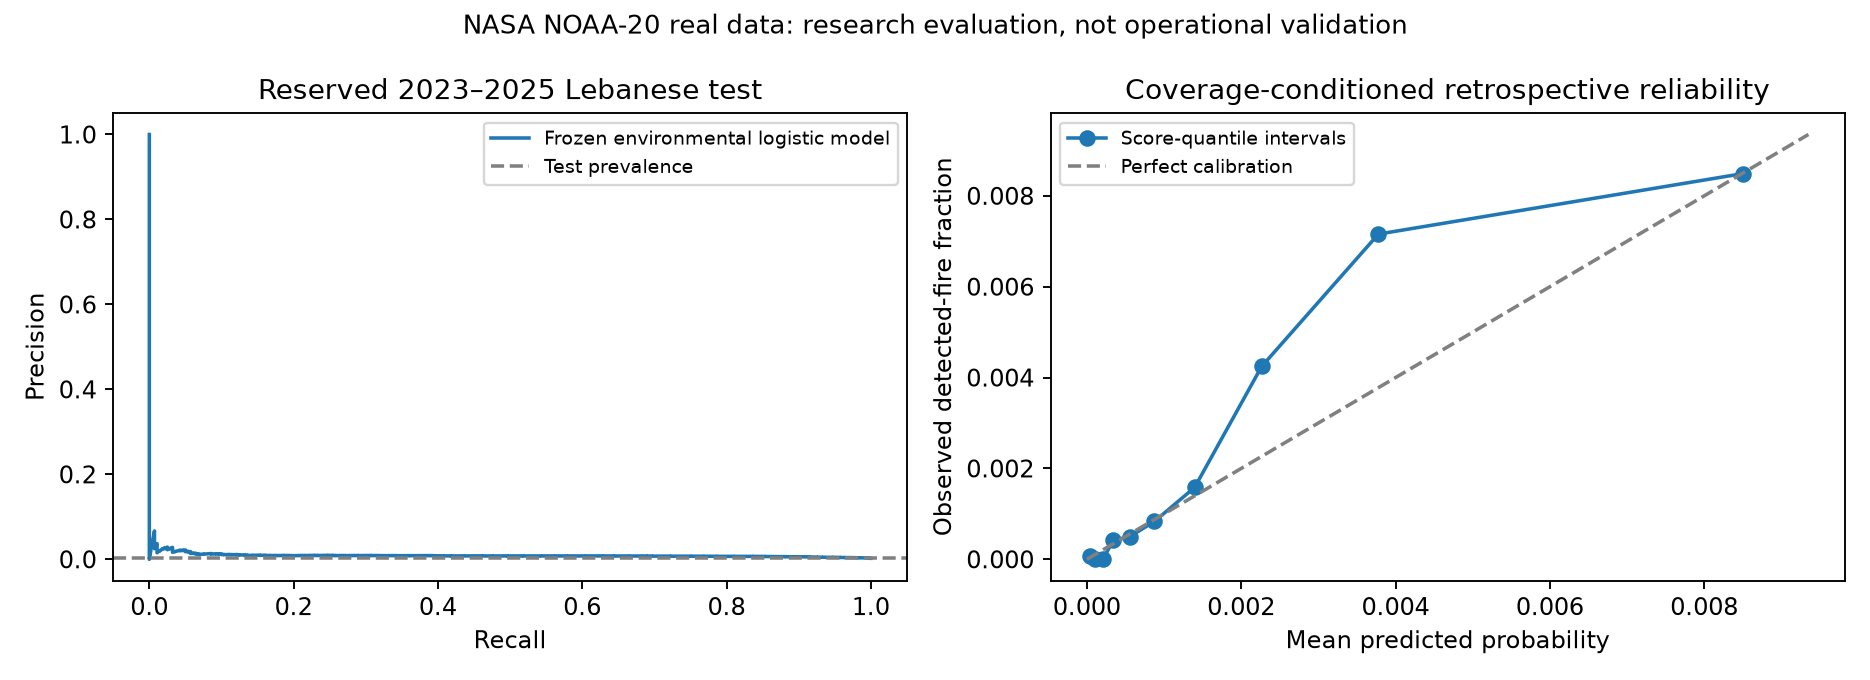

In [5]:
result = review(DATA, MODELS, DATA / 'review')
assert result['release']['approved'] is False
print('Production release failures:', result['release']['failures'])
display(pd.DataFrame(result['quantile_reliability']))
display(Image(filename=str(DATA / 'review/evaluation.png')))

## Genuine issued forecast: explicit research transfer only
The GEOS cycle was issued 14 November 2026 at 00 UTC; the target window is 15–16 November UTC. All 24 hourly meteorology, rain and cloud intervals were downloaded and checked. Retrieval timestamps precede prediction. The model was validated on POWER historical weather, so every output must retain the GEOS source-transfer and retrospective warnings. This run does not validate operational forecasting skill.

,cell_id,prediction_time,probability,flags
0,1230_2151,2026-11-15 00:00:00+00:00,0.002002,outside_validated_weather_source;RETROSPECTIVE...
1,1242_2161,2026-11-15 00:00:00+00:00,0.000157,outside_validated_weather_source;RETROSPECTIVE...
2,1242_2160,2026-11-15 00:00:00+00:00,0.000106,outside_validated_weather_source;RETROSPECTIVE...
3,1242_2159,2026-11-15 00:00:00+00:00,0.000581,outside_validated_weather_source;RETROSPECTIVE...
4,1242_2158,2026-11-15 00:00:00+00:00,0.001695,outside_validated_weather_source;RETROSPECTIVE...


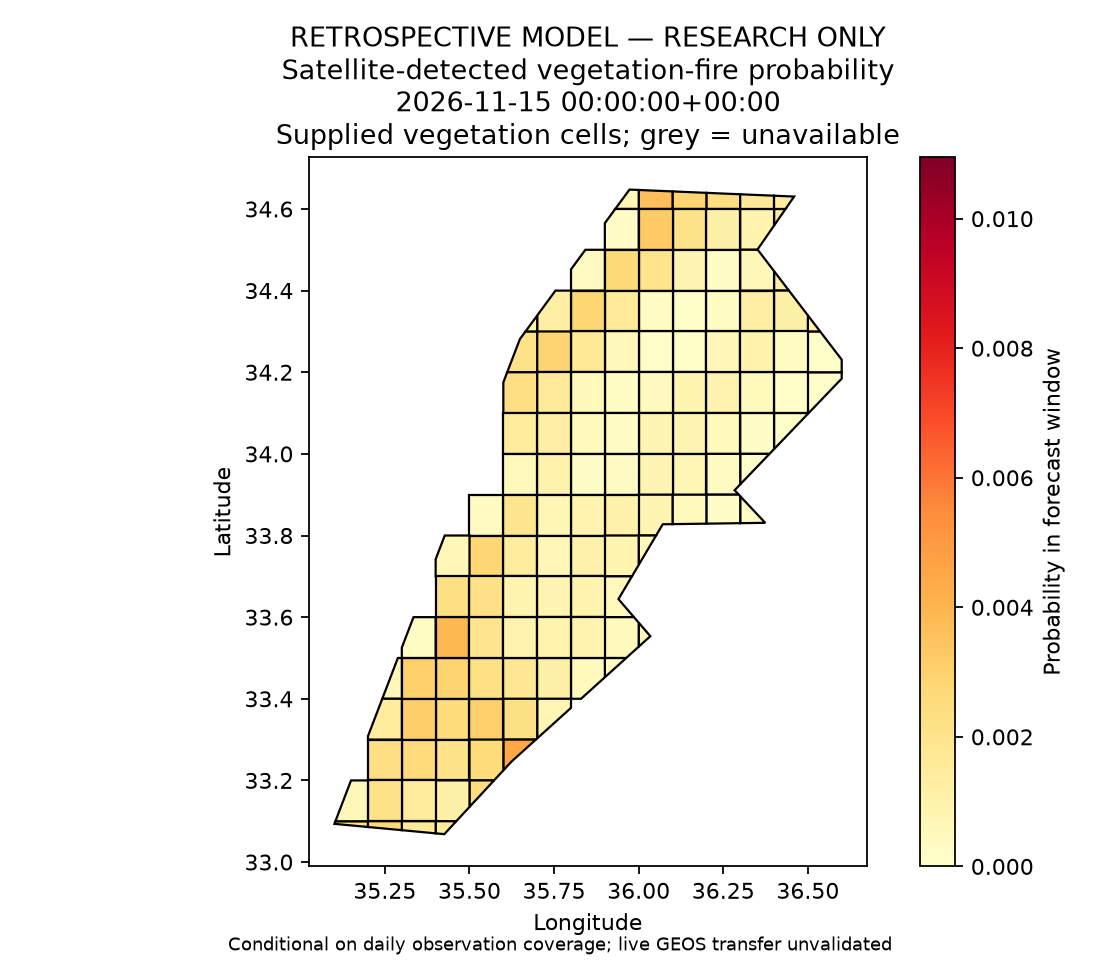

In [6]:
rows = predict(MODELS / 'model.joblib', ROOT / 'data/live-forecast-features/forecast-features.csv', ROOT / 'outputs/live-research-risk')
risk = pd.DataFrame(rows)
assert risk['flags'].str.contains('RETROSPECTIVE_MODEL_NOT_OPERATIONALLY_VALIDATED').all()
assert risk['flags'].str.contains('outside_validated_weather_source').all()
display(risk[['cell_id','prediction_time','probability','flags']].head())
display(Image(filename=str(ROOT / 'outputs/live-research-risk/risk.png')))

## What remains unverified
A multi-year NASA issued-meteorology forecast archive, historical publication/availability evidence, incident independence and acceptable calibration/decision performance are still missing. Comparable-region and buffered geographic-transfer experiments have not been run. Full NDVI history, independent burned-area/incident validation and authoritative facility/conflict adjudication remain future work. The API intentionally returns readiness 503 for this retrospective artifact. See `../docs/statecharts.md` for the complete logic and `../../decisions.md` for choices.